# Разведочный анализ данных (EDA): Hotel Booking Demand
**Цель этапа:** Получить интуицию о данных, выявить аномалии, пропуски, изучить взаимосвязи признаков с целевой переменной и выявить потенциальные утечки данных (Data Leakage) перед построением ML-моделей.

**Датасет:** Hotel Booking Demand (TidyTuesday), бронирования двух португальских отелей (2015–2017 гг.).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Настройка стиля графиков
sns.set_theme(style="whitegrid", context="notebook", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

In [3]:
df = pd.read_csv("https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv")
print(f"Размер датасета: {df.shape}")
display(df.head(3))

Размер датасета: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02


# Структурная информация датасета

In [4]:
print("Типы данных признаков \n")
df.info()

Типы данных признаков 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64

In [5]:
missing_stats = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percent': (df.isnull().sum() / len(df)) * 100
})
missing_stats = missing_stats[missing_stats['Missing_Count'] > 0].sort_values(by='Missing_Percent', ascending=False)
display(missing_stats.style.set_caption("Таблица 2: Анализ пропусков"))

,Missing_Count,Missing_Percent
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350


In [6]:
describe_df = df.describe(include='all').T
display(describe_df.style.set_caption("Таблица 3: Описательные статистики всех признаков датасета"))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,nan,nan,nan,nan,nan,nan,nan
is_canceled,119390.000000,nan,nan,nan,0.370416,0.482918,0.000000,0.000000,0.000000,1.000000,1.000000
lead_time,119390.000000,nan,nan,nan,104.011416,106.863097,0.000000,18.000000,69.000000,160.000000,737.000000
arrival_date_year,119390.000000,nan,nan,nan,2016.156554,0.707476,2015.000000,2016.000000,2016.000000,2017.000000,2017.000000
arrival_date_month,119390,12,August,13877,nan,nan,nan,nan,nan,nan,nan
arrival_date_week_number,119390.000000,nan,nan,nan,27.165173,13.605138,1.000000,16.000000,28.000000,38.000000,53.000000
arrival_date_day_of_month,119390.000000,nan,nan,nan,15.798241,8.780829,1.000000,8.000000,16.000000,23.000000,31.000000
stays_in_weekend_nights,119390.000000,nan,nan,nan,0.927599,0.998613,0.000000,0.000000,1.000000,2.000000,19.000000
stays_in_week_nights,119390.000000,nan,nan,nan,2.500302,1.908286,0.000000,1.000000,2.000000,3.000000,50.000000
adults,119390.000000,nan,nan,nan,1.856403,0.579261,0.000000,2.000000,2.000000,2.000000,55.000000


#Анализ целевой переменной и аномалий

In [54]:
print("Таблица 4: Соотношение reservation_status и is_canceled")
display(pd.crosstab(df['reservation_status'], df['is_canceled']))

Таблица 4: Соотношение reservation_status и is_canceled


is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


In [8]:
zero_adults_mask = df['adults'] == 0
zero_adults_count = zero_adults_mask.sum()

print(f"Количество записей с adults == 0: {zero_adults_count} \n")

if zero_adults_count > 0:
    display(
        df.loc[zero_adults_mask, ['hotel', 'adults', 'children', 'babies', 'is_canceled']]
        .head(10)
        .style.set_caption("Таблица 5: Примеры записей с нулевым количеством взрослых")
    )

Количество записей с adults == 0: 403 



,hotel,adults,children,babies,is_canceled
2224,Resort Hotel,0,0.000000,0,0
2409,Resort Hotel,0,0.000000,0,0
3181,Resort Hotel,0,0.000000,0,0
3684,Resort Hotel,0,0.000000,0,0
3708,Resort Hotel,0,0.000000,0,0
4127,Resort Hotel,0,0.000000,0,1
9376,Resort Hotel,0,0.000000,0,1
31765,Resort Hotel,0,0.000000,0,0
32029,Resort Hotel,0,0.000000,0,0
32827,Resort Hotel,0,0.000000,0,0


In [53]:
# Анализ экстремальных значений ADR
adr_negative_count = (df['adr'] < 0).sum()
adr_extreme_count = (df['adr'] > 1000).sum()

print(f"Записей с отрицательным ADR: {adr_negative_count}")
print(f"Записей с ADR > 1000: {adr_extreme_count}")

Записей с отрицательным ADR: 1
Записей с ADR > 1000: 1


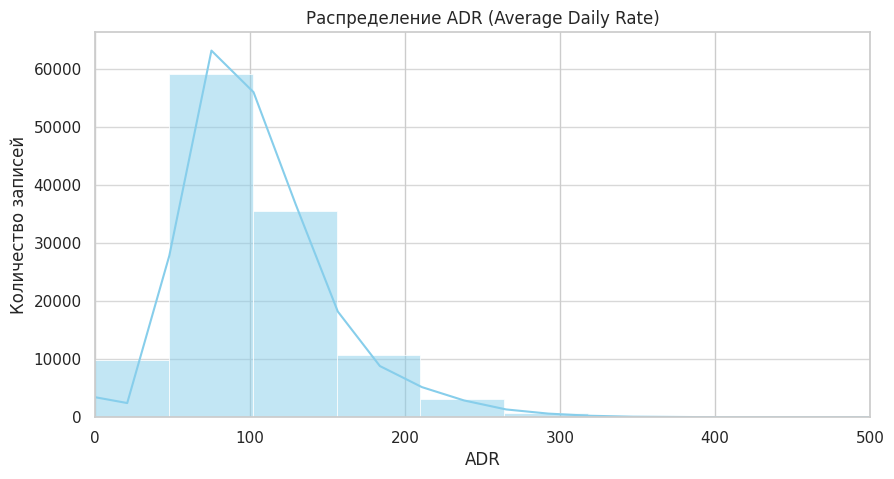

In [10]:
# Визуализация распределения ADR с ограничением оси для наглядности основной массы данных
plt.figure(figsize=(10, 5))
sns.histplot(df['adr'], bins=100, kde=True, color='skyblue')

plt.title('Распределение ADR (Average Daily Rate)')
plt.xlabel('ADR')
plt.ylabel('Количество записей')
plt.xlim(0, 500)
plt.grid(axis='y', alpha=0.75)

plt.show()

# Связь целевой переменной и признаков

/tmp/ipykernel_1545/50734134.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='hotel', y='is_canceled', data=df, errorbar=None, palette='muted')


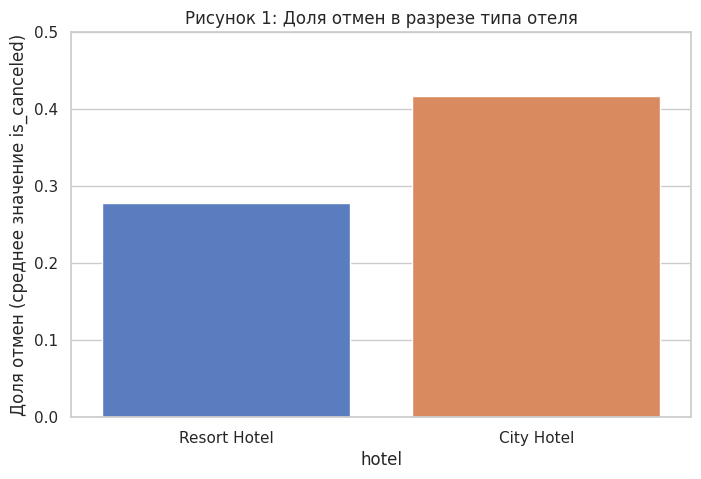

In [41]:
plt.figure(figsize=(8, 5))
sns.barplot(x='hotel', y='is_canceled', data=df, errorbar=None, palette='muted')
plt.title('Рисунок 1: Доля отмен в разрезе типа отеля')
plt.ylabel('Доля отмен (среднее значение is_canceled)')
plt.ylim(0, 0.5)
plt.show()

/tmp/ipykernel_1545/248277750.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='deposit_type', y='is_canceled', data=df, errorbar=None, palette='muted')


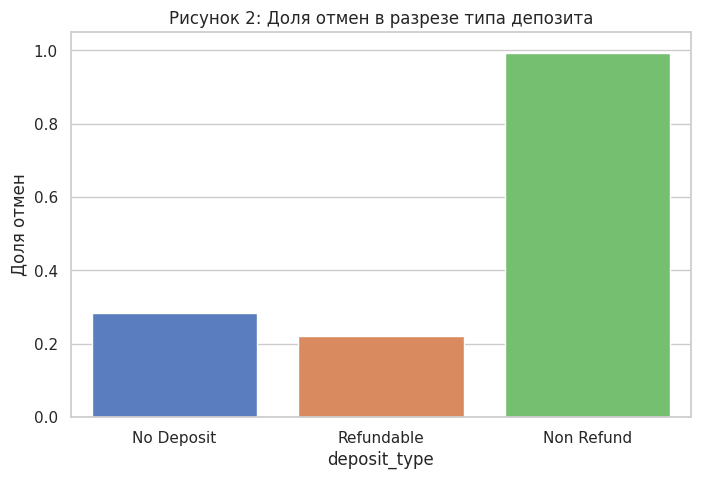

In [42]:
plt.figure(figsize=(8, 5))
sns.barplot(x='deposit_type', y='is_canceled', data=df, errorbar=None, palette='muted')
plt.title('Рисунок 2: Доля отмен в разрезе типа депозита')
plt.ylabel('Доля отмен')
plt.ylim(0, 1.05)
plt.show()

/tmp/ipykernel_1545/983954956.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='lead_time_bin', y='is_canceled', data=df, errorbar=None, palette='muted')


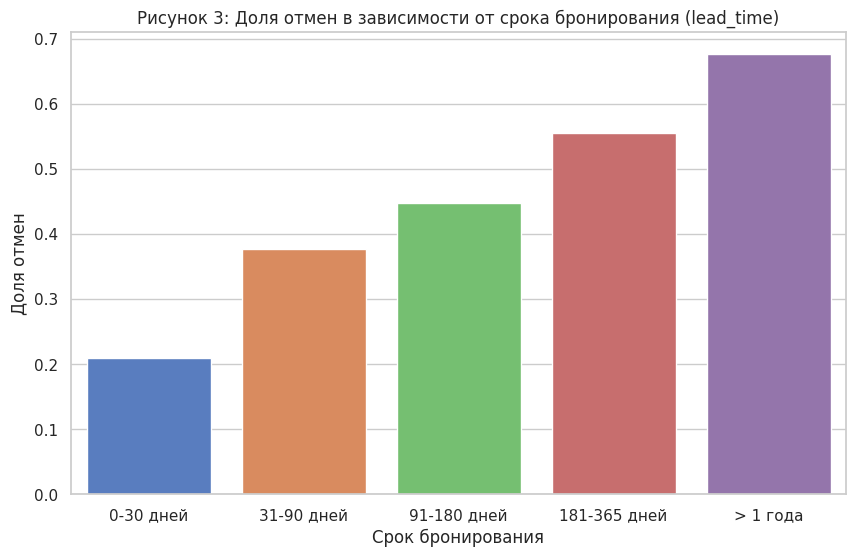

In [24]:
df['lead_time_bin'] = pd.cut(df['lead_time'],
                             bins=[0, 30, 90, 180, 365, 1000],
                             labels=['0-30 дней', '31-90 дней', '91-180 дней', '181-365 дней', '> 1 года'])

plt.figure(figsize=(10, 6))
sns.barplot(x='lead_time_bin', y='is_canceled', data=df, errorbar=None, palette='muted')
plt.title('Рисунок 3: Доля отмен в зависимости от срока бронирования (lead_time)')
plt.ylabel('Доля отмен')
plt.xlabel('Срок бронирования')
plt.show()

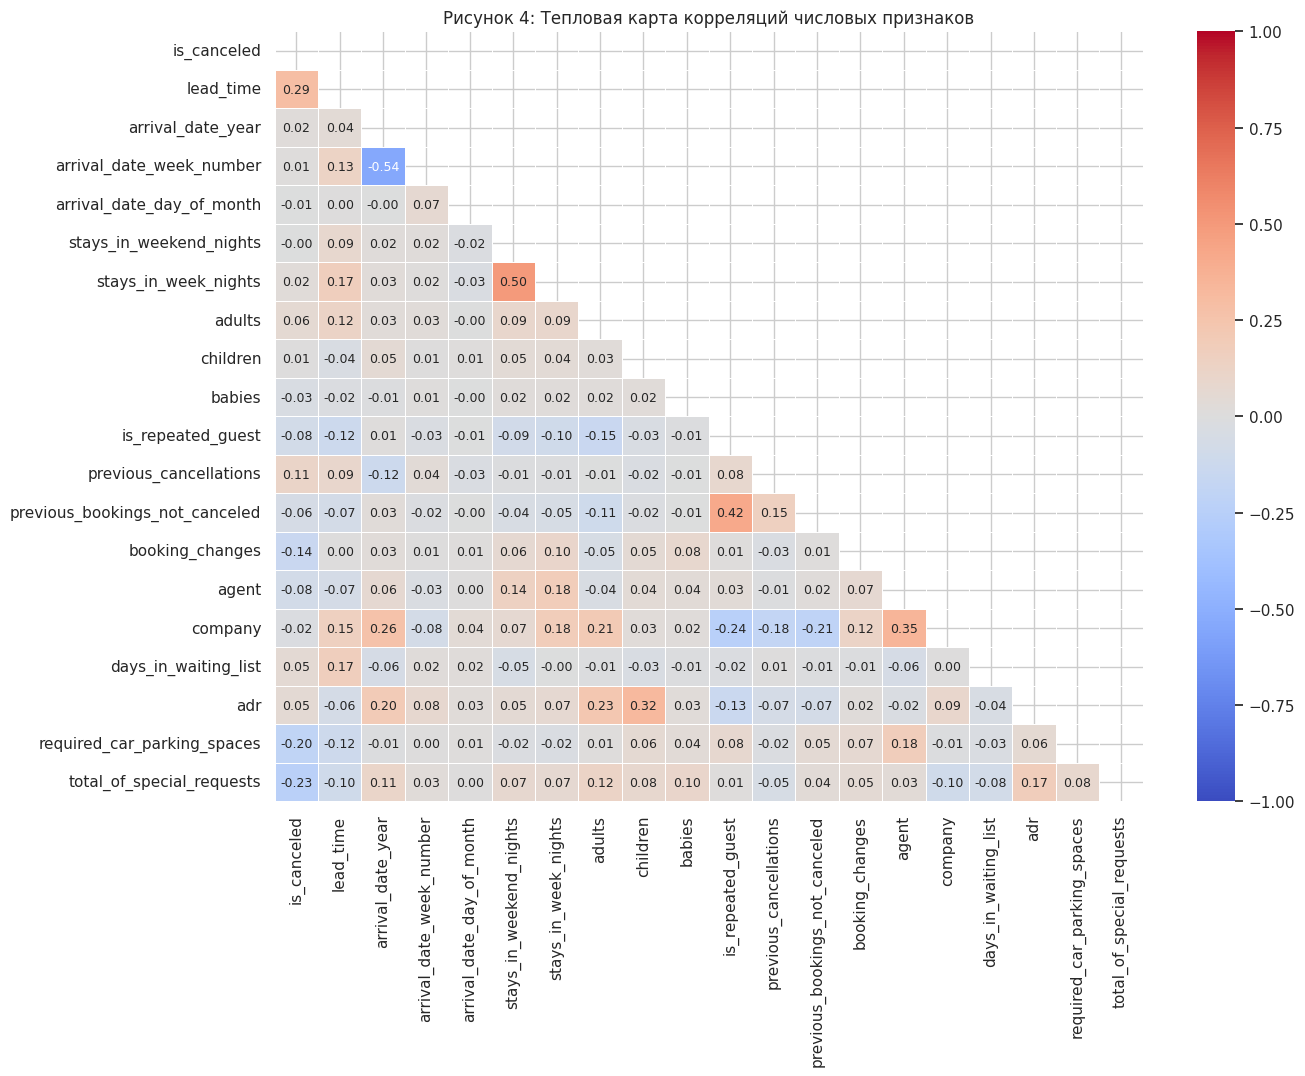

In [22]:
# Тепловая карта корреляций только для числовых признаков
numeric_cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(14, 10))
correlation_matrix = df[numeric_cols].corr()
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    annot_kws={"size": 9}
)
plt.title('Рисунок 4: Тепловая карта корреляций числовых признаков')
plt.show()

# Анализ параметров с возможной утечкой данных

In [43]:
print("Таблица 6: Количество записей по типу депозита")
display(df['deposit_type'].value_counts().to_frame())

Таблица 6: Количество записей по типу депозита


,count
deposit_type,
No Deposit,104641
Non Refund,14587
Refundable,162


In [40]:
print("Таблица 7: Доля отмен для Non Refund по отелям")
non_refund_data = df[df['deposit_type'] == 'Non Refund']
display(non_refund_data.groupby('hotel')['is_canceled'].mean().to_frame())

Таблица 7: Доля отмен для Non Refund по отелям


,is_canceled
hotel,
City Hotel,0.998135
Resort Hotel,0.959860


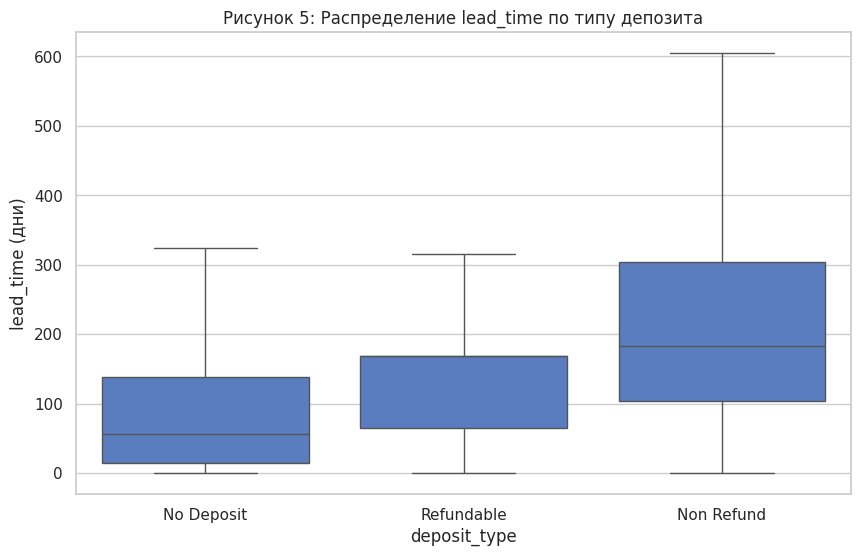

In [34]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='deposit_type', y='lead_time', data=df, showfliers=False)
plt.title('Рисунок 5: Распределение lead_time по типу депозита')
plt.ylabel('lead_time (дни)')
plt.show()

In [39]:
print("Таблица 8: Среднее количество изменений брони по типу депозита")
display(df.groupby('deposit_type')['booking_changes'].mean().to_frame())

Таблица 8: Среднее количество изменений брони по типу депозита


,booking_changes
deposit_type,
No Deposit,0.249634
Non Refund,0.012477
Refundable,0.592593


In [38]:
print("Таблица 9: Доля отмен по deposit_type")
display(df.groupby('deposit_type')['is_canceled'].mean().to_frame())

Таблица 9: Доля отмен по deposit_type


,is_canceled
deposit_type,
No Deposit,0.283770
Non Refund,0.993624
Refundable,0.222222


In [37]:
# Пробуем сгладить влияние параметра с утечкой
df['has_deposit'] = (df['deposit_type'] != 'No Deposit').astype(int)

print("Таблица 10: Доля отмен по has_deposit")
display(df.groupby('has_deposit')['is_canceled'].mean().to_frame())

Таблица 10: Доля отмен по has_deposit


,is_canceled
has_deposit,
0,0.283770
1,0.985152


In [45]:
leakage_candidates = [
    'assigned_room_type',      # может измениться при заезде
    'reservation_status_date', # точно после бронирования
    'booking_changes',         # меняется со временем
    'days_in_waiting_list'     # меняется со временем
]

print("Анализ потенциальных утечек данных")

for col in leakage_candidates:
    print(f"--- {col} ---")
    print(f"Уникальных значений: {df[col].nunique()}")
    print(f"Первые 10 значений:")
    print(df[col].value_counts().head(3))
    print()

Анализ потенциальных утечек данных
--- assigned_room_type ---
Уникальных значений: 12
Первые 10 значений:
assigned_room_type
A    74053
D    25322
E     7806
Name: count, dtype: int64

--- reservation_status_date ---
Уникальных значений: 926
Первые 10 значений:
reservation_status_date
2015-10-21    1461
2015-07-06     805
2016-11-25     790
Name: count, dtype: int64

--- booking_changes ---
Уникальных значений: 21
Первые 10 значений:
booking_changes
0    101314
1     12701
2      3805
Name: count, dtype: int64

--- days_in_waiting_list ---
Уникальных значений: 128
Первые 10 значений:
days_in_waiting_list
0     115692
39       227
58       164
Name: count, dtype: int64



In [48]:
room_comparison = pd.crosstab(
    df['reserved_room_type'],
    df['assigned_room_type'],
    margins=True
)

display(room_comparison.style.set_caption("Таблица 11: Соответствие зарезервированного и назначенного типа номера"))

room_changed = (df['reserved_room_type'] != df['assigned_room_type']).mean()
print()
print(f"Доля бронирований, где тип номера изменился: {room_changed:.4%}")

assigned_room_type,A,B,C,D,E,F,G,H,I,K,L,P,All
reserved_room_type,,,,,,,,,,,,,
A,73598,1123,1447,7548,1156,417,186,94,215,210,0,0,85994
B,111,988,0,5,2,2,8,0,0,2,0,0,1118
C,5,2,883,6,4,2,10,10,10,0,0,0,932
D,312,27,34,17736,686,204,82,9,67,44,0,0,19201
E,15,3,8,22,5923,404,100,4,40,16,0,0,6535
F,6,17,0,4,31,2707,116,3,10,3,0,0,2897
G,5,2,2,0,4,14,2041,7,15,4,0,0,2094
H,0,0,0,1,0,0,10,584,6,0,0,0,601
L,1,1,1,0,0,1,0,1,0,0,1,0,6



Доля бронирований, где тип номера изменился: 12.4943%


In [52]:
month_map = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4,
    'May': 5, 'June': 6, 'July': 7, 'August': 8,
    'September': 9, 'October': 10, 'November': 11, 'December': 12
}

df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' +
    df['arrival_date_month'].map(month_map).astype(str) + '-' +
    df['arrival_date_day_of_month'].astype(str)
)

df['booking_date'] = df['arrival_date'] - pd.to_timedelta(df['lead_time'], unit='D')

print(f"Диапазон: {df['booking_date'].min().date()} до {df['booking_date'].max().date()}")

Диапазон: 2013-06-24 до 2017-08-31


In [51]:
print("Анализ reservation_status_date \n")

df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])
print(f"Диапазон дат изменения статуса: {df['reservation_status_date'].min()} до {df['reservation_status_date'].max()}")
print(f"Диапазон дат бронирования (booking_date): {df['booking_date'].min()} до {df['booking_date'].max()}")

# Проверяем, есть ли случаи, когда статус изменился ДО бронирования
status_before_booking = (df['reservation_status_date'] < df['booking_date']).sum()
print(f"Количество записей, где статус изменился ДО бронирования: {status_before_booking}")

# Проверяем, есть ли случаи, когда статус изменился ПОСЛЕ заезда
status_after_arrival = (df['reservation_status_date'] > df['arrival_date']).sum()
print(f"Количество записей, где статус изменился ПОСЛЕ заезда: {status_after_arrival}")

Анализ reservation_status_date 

Диапазон дат изменения статуса: 2014-10-17 00:00:00 до 2017-09-14 00:00:00
Диапазон дат бронирования (booking_date): 2013-06-24 00:00:00 до 2017-08-31 00:00:00

Количество записей, где статус изменился ДО бронирования: 0
Количество записей, где статус изменился ПОСЛЕ заезда: 74460


In [61]:
# Сравнительная статистика lead_time для отмененных и успешных бронирований
lead_time_stats = df.groupby('is_canceled')['lead_time'].agg(['count', 'mean', 'median', 'max']).round(1)

# Переименуем индексы для наглядности
lead_time_stats.index = ['0: Успешный заезд', '1: Отмена / No-Show']

display(lead_time_stats.style.set_caption("Таблица 12: Сравнение сроков бронирования по факту заезда"))

,count,mean,median,max
0: Успешный заезд,75166,80.000000,45.000000,737
1: Отмена / No-Show,44224,144.800000,113.000000,629


/tmp/ipykernel_1545/2459352178.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


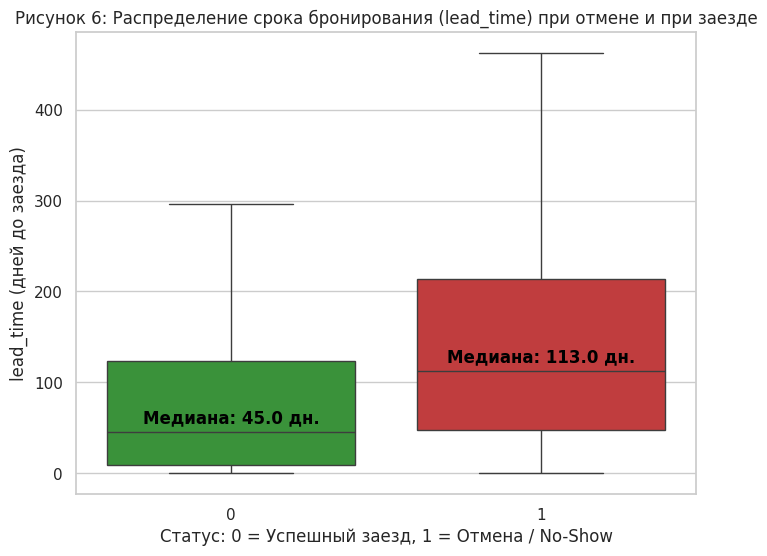

In [62]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    x='is_canceled',
    y='lead_time',
    data=df,
    showfliers=False,
    palette=['#2ca02c', '#d62728']
)

plt.title('Рисунок 6: Распределение срока бронирования (lead_time) при отмене и при заезде')
plt.xlabel('Статус: 0 = Успешный заезд, 1 = Отмена / No-Show')
plt.ylabel('lead_time (дней до заезда)')

medians = df.groupby('is_canceled')['lead_time'].median().values
for i, median in enumerate(medians):
    plt.text(i, median + 10, f'Медиана: {median} дн.',
             horizontalalignment='center', size='medium', color='black', weight='semibold')

plt.show()

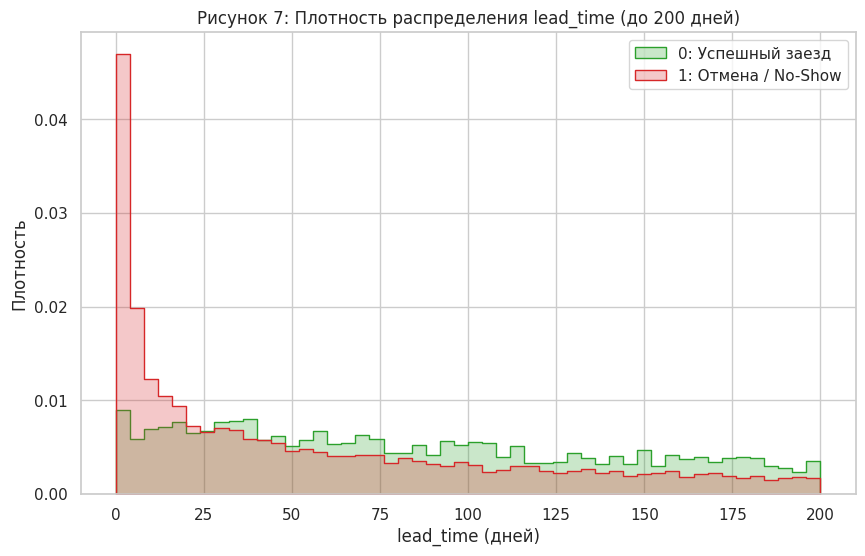

In [63]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df[df['lead_time'] <= 200], # Фильтруем экстремальные хвосты
    x='lead_time',
    hue='is_canceled',
    element='step',
    stat='density',
    common_norm=False,
    palette=['#d62728', '#2ca02c']
)

plt.title('Рисунок 7: Плотность распределения lead_time (до 200 дней)')
plt.xlabel('lead_time (дней)')
plt.ylabel('Плотность')
plt.legend(['0: Успешный заезд', '1: Отмена / No-Show'])
plt.show()